In [16]:
!pip install imbalanced-learn


In [17]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
from google.colab import files

uploaded = files.upload()

Saving water_potability_class_balanced.csv to water_potability_class_balanced (1).csv


In [27]:
df = pd.read_csv("water_potability_class_balanced (1).csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (9362, 27)


,sample_id,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,...,is_high_solids,is_high_turbidity,is_high_organic,is_high_chloramines,ph_hardness_ratio,solids_conductivity_ratio,organic_turbidity_ratio,water_quality_score,quality_grade,risk_factor_count
0,3422,10.6075,180.0693,21741.2983,6.9690,340.4020,455.4743,16.3926,33.6693,3.9449,...,1,0,1,0,0.0586,47.6287,4.0527,45,2,3
1,9212,8.4957,221.8667,24960.7647,6.1700,341.5504,388.5389,16.0741,35.9161,3.8698,...,1,0,1,0,0.0381,64.0777,4.0491,65,3,3
2,1988,7.6114,215.3860,12012.0025,11.0270,397.7865,317.4033,12.0742,58.1001,3.5904,...,0,0,0,1,0.0352,37.7257,3.2718,80,3,2
3,9989,6.4915,198.1058,18819.7433,7.3373,333.1931,256.4398,13.7740,52.5501,3.2808,...,0,0,0,0,0.0326,73.1035,4.0742,80,3,1
4,9672,5.1375,110.5500,11162.9412,5.7541,389.0479,314.6003,13.1551,81.3481,4.4753,...,0,0,0,0,0.0461,35.3705,2.8752,45,2,1


In [28]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["quality_grade"].value_counts().sort_index())

Columns:
['sample_id', 'ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability', 'ph_is_normal', 'ph_level', 'hardness_level', 'solids_level', 'turbidity_level', 'is_high_hardness', 'is_high_solids', 'is_high_turbidity', 'is_high_organic', 'is_high_chloramines', 'ph_hardness_ratio', 'solids_conductivity_ratio', 'organic_turbidity_ratio', 'water_quality_score', 'quality_grade', 'risk_factor_count']

Missing values:
sample_id                    0
ph                           0
Hardness                     0
Solids                       0
Chloramines                  0
Sulfate                      0
Conductivity                 0
Organic_carbon               0
Trihalomethanes              0
Turbidity                    0
Potability                   0
ph_is_normal                 0
ph_level                     0
hardness_level               0
solids_level                 0
turbidity_level              0
is_high_ha

In [29]:
original_features = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

X = df[original_features]
y = df["quality_grade"]

print("Input features:")
print(original_features)

print("\nTarget:")
print("quality_grade")

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Input features:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

Target:
quality_grade

X shape: (9362, 9)
y shape: (9362,)


In [30]:
X = X.copy()

for column in X.columns:
    X[column] = X[column].fillna(X[column].median())

print("Missing values after handling:")
print(X.isnull().sum())

Missing values after handling:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
dtype: int64


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7489, 9)
Testing data: (1873, 9)


In [32]:
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train,
    y_train
)

print("Before balancing:")
print(y_train.value_counts().sort_index())

print("\nAfter balancing:")
print(y_train_balanced.value_counts().sort_index())

Before balancing:
quality_grade
1    1829
2    2986
3    2281
4     393
Name: count, dtype: int64

After balancing:
quality_grade
1    2986
2    2986
3    2986
4    2986
Name: count, dtype: int64


In [33]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

random forest


In [34]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_balanced, y_train_balanced)

rf_pred = rf_model.predict(X_test)

print("Random Forest")
print(classification_report(y_test, rf_pred))

Random Forest
              precision    recall  f1-score   support

           1       0.99      0.96      0.98       457
           2       0.96      0.98      0.97       747
           3       0.97      0.98      0.98       570
           4       0.99      0.95      0.97        99

    accuracy                           0.97      1873
   macro avg       0.98      0.97      0.97      1873
weighted avg       0.97      0.97      0.97      1873



decision tree

In [35]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_balanced, y_train_balanced)

dt_pred = dt_model.predict(X_test)

print("Decision Tree")
print(classification_report(y_test, dt_pred))

Decision Tree
              precision    recall  f1-score   support

           1       0.96      0.96      0.96       457
           2       0.95      0.95      0.95       747
           3       0.96      0.97      0.96       570
           4       0.99      0.97      0.98        99

    accuracy                           0.96      1873
   macro avg       0.96      0.96      0.96      1873
weighted avg       0.96      0.96      0.96      1873



gradient boosting



In [36]:
gb_model = GradientBoostingClassifier(
    random_state=42
)

gb_model.fit(X_train_balanced, y_train_balanced)

gb_pred = gb_model.predict(X_test)

print("Gradient Boosting")
print(classification_report(y_test, gb_pred))

Gradient Boosting
              precision    recall  f1-score   support

           1       0.96      0.96      0.96       457
           2       0.93      0.88      0.91       747
           3       0.88      0.93      0.90       570
           4       0.93      0.97      0.95        99

    accuracy                           0.92      1873
   macro avg       0.93      0.94      0.93      1873
weighted avg       0.92      0.92      0.92      1873



logistic regresssion

In [37]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train_balanced)

lr_pred = lr_model.predict(X_test_scaled)

print("Logistic Regression")
print(classification_report(y_test, lr_pred))

Logistic Regression
              precision    recall  f1-score   support

           1       0.51      0.65      0.57       457
           2       0.48      0.30      0.37       747
           3       0.49      0.40      0.44       570
           4       0.21      0.76      0.33        99

    accuracy                           0.44      1873
   macro avg       0.42      0.53      0.43      1873
weighted avg       0.48      0.44      0.44      1873



knn

In [38]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train_balanced)

knn_pred = knn_model.predict(X_test_scaled)

print("KNN")
print(classification_report(y_test, knn_pred))

KNN
              precision    recall  f1-score   support

           1       0.81      0.84      0.82       457
           2       0.83      0.72      0.77       747
           3       0.78      0.81      0.79       570
           4       0.58      0.92      0.71        99

    accuracy                           0.79      1873
   macro avg       0.75      0.82      0.78      1873
weighted avg       0.80      0.79      0.79      1873



svm



In [39]:
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train_balanced)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM")
print(classification_report(y_test, svm_pred))

SVM
              precision    recall  f1-score   support

           1       0.81      0.86      0.83       457
           2       0.79      0.68      0.73       747
           3       0.73      0.78      0.75       570
           4       0.62      0.93      0.74        99

    accuracy                           0.76      1873
   macro avg       0.74      0.81      0.76      1873
weighted avg       0.77      0.76      0.76      1873



In [40]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Decision Tree",
        "Gradient Boosting",
        "Logistic Regression",
        "KNN",
        "SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, gb_pred),
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],

    "Precision": [
        precision_score(y_test, rf_pred, average="weighted"),
        precision_score(y_test, dt_pred, average="weighted"),
        precision_score(y_test, gb_pred, average="weighted"),
        precision_score(y_test, lr_pred, average="weighted"),
        precision_score(y_test, knn_pred, average="weighted"),
        precision_score(y_test, svm_pred, average="weighted")
    ],

    "Recall": [
        recall_score(y_test, rf_pred, average="weighted"),
        recall_score(y_test, dt_pred, average="weighted"),
        recall_score(y_test, gb_pred, average="weighted"),
        recall_score(y_test, lr_pred, average="weighted"),
        recall_score(y_test, knn_pred, average="weighted"),
        recall_score(y_test, svm_pred, average="weighted")
    ],

    "F1 Score": [
        f1_score(y_test, rf_pred, average="weighted"),
        f1_score(y_test, dt_pred, average="weighted"),
        f1_score(y_test, gb_pred, average="weighted"),
        f1_score(y_test, lr_pred, average="weighted"),
        f1_score(y_test, knn_pred, average="weighted"),
        f1_score(y_test, svm_pred, average="weighted")
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.974373,0.974554,0.974373,0.974380
1,Decision Tree,0.957822,0.957850,0.957822,0.957829
2,Gradient Boosting,0.920982,0.921862,0.920982,0.920964
3,Logistic Regression,0.439936,0.477324,0.439936,0.438519
4,KNN,0.787507,0.795963,0.787507,0.788010
5,SVM,0.764015,0.769542,0.764015,0.762967


In [41]:
results_percentage = results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    results_percentage[column] = (
        results_percentage[column] * 100
    ).round(2)

results_percentage

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,97.44,97.46,97.44,97.44
1,Decision Tree,95.78,95.78,95.78,95.78
2,Gradient Boosting,92.10,92.19,92.10,92.10
3,Logistic Regression,43.99,47.73,43.99,43.85
4,KNN,78.75,79.60,78.75,78.80
5,SVM,76.40,76.95,76.40,76.30


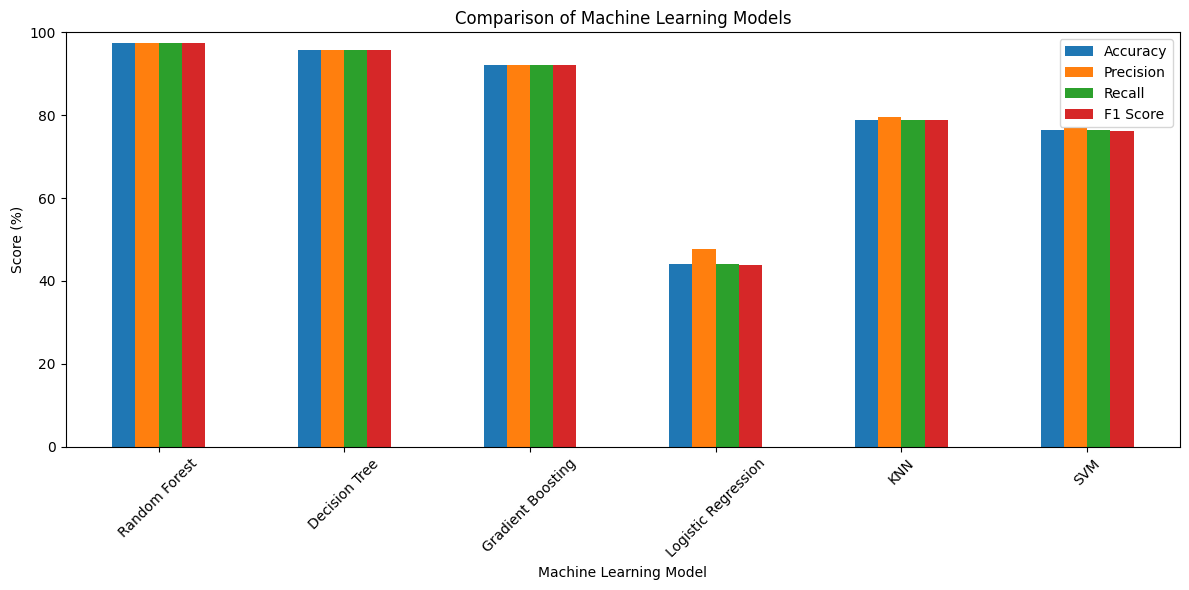

In [42]:
results_percentage.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

In [44]:
results_percentage.to_csv(
    "water_quality_model_comparison.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [46]:
from google.colab import files

results_percentage.to_csv(
    "water_quality_model_comparison.csv",
    index=False
)

files.download("water_quality_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Random Forest
[[441  16   0   0]
 [  5 732  10   0]
 [  0  11 558   1]
 [  0   0   5  94]]


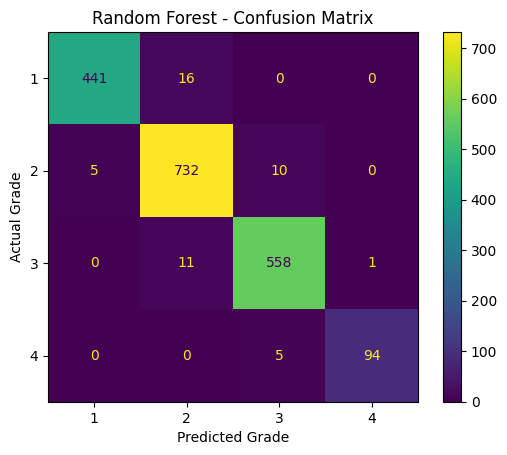


Decision Tree
[[437  20   0   0]
 [ 19 710  18   0]
 [  1  17 551   1]
 [  0   0   3  96]]


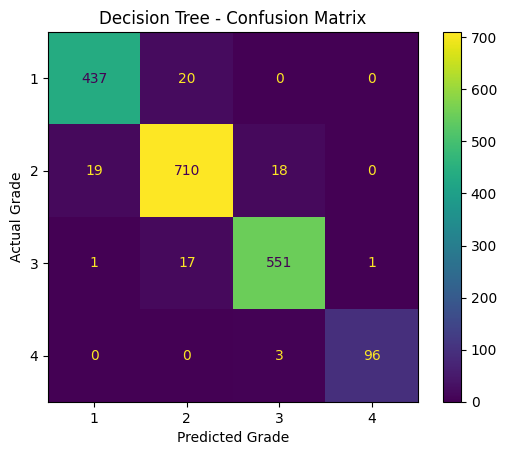


Gradient Boosting
[[439  18   0   0]
 [ 17 660  70   0]
 [  0  33 530   7]
 [  0   0   3  96]]


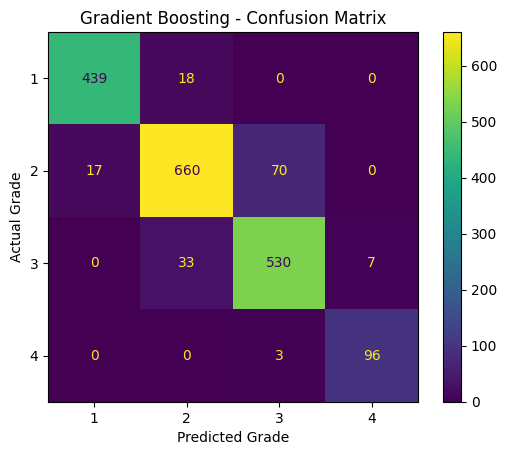


Logistic Regression
[[295 105  39  18]
 [231 226 175 115]
 [ 56 134 228 152]
 [  0   1  23  75]]


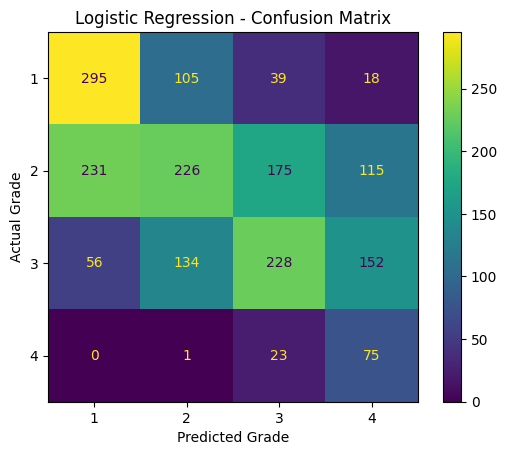


KNN
[[385  59  11   2]
 [ 76 539 112  20]
 [ 17  50 460  43]
 [  0   0   8  91]]


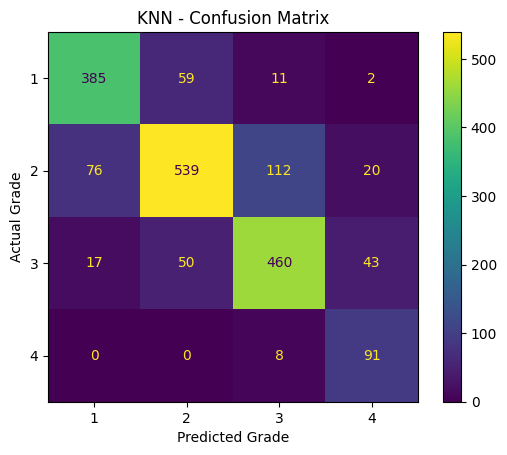


SVM
[[391  62   4   0]
 [ 85 505 152   5]
 [  4  71 443  52]
 [  0   0   7  92]]


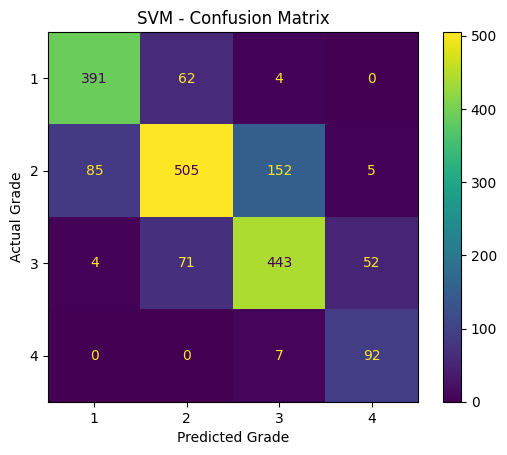

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Store all trained models
models = {
    "Random Forest": rf_model,
    "Decision Tree": dt_model,
    "Gradient Boosting": gb_model,
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "SVM": svm_model
}

# Generate confusion matrix for every model
for name, model in models.items():

    # Use scaled data for Logistic Regression, KNN and SVM
    if name in ["Logistic Regression", "KNN", "SVM"]:
        y_pred = model.predict(X_test_scaled)
    else:
        y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[1, 2, 3, 4])

    print("\n" + "="*50)
    print(name)
    print("="*50)
    print(cm)

    # Display confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[1, 2, 3, 4]
    )

    disp.plot()
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted Grade")
    plt.ylabel("Actual Grade")
    plt.show()